# Haberman's Survival: what does the lymph-node count tell us?

**The question:** 306 women had breast-cancer surgery at the University of Chicago's Billings Hospital between 1958 and 1970. Using only facts known *on the day of surgery*, what separates the patients who lived 5+ years from those who did not?

**How this notebook works.** Every section starts with a plain-English explanation, then the code, then how to read the result. The flow is:

1. The analogy
2. Hypotheses
3. Look at the data
4. Statistical tests
5. Visual evidence
6. A baseline model, with no cheating
7. Does a bigger model help?
8. Takeaways and limitations

**Run it:** `uv run jupyter lab ML/haberman-survival/haberman_survival.ipynb` (or *Run All* in any Jupyter). The data downloads itself on the first run.

## 1. 💡 The simple analogy

Your armpit has small filters called **lymph nodes**. Think of them as **security checkpoints on a road out of town**.

- During surgery, the doctor checks the checkpoints. If cancer cells are stuck at *many* of them, those cells were already travelling, so the cancer had a head start.
- If *no* checkpoint caught anything, the cancer probably had not left home yet.

So our question is simple: **does the number of "positive" checkpoints (positive axillary nodes) predict who is alive five years later?** We will also ask whether the patient's **age** or the **year of the operation** tells us anything extra.

## 2. Setup

*What:* imports and a few named constants. *Why:* putting numbers like the random seed in one place means nobody has to hunt for "magic numbers" later, and the results are reproducible. Fixing the seed makes the bootstrap and the cross-validation give the same answer every time you run the notebook.

In [1]:
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/haberman/haberman.data"
DATA_PATH = Path("data/haberman.csv")
OUT_DIR = Path("outputs")
SEED = 42
N_BOOTSTRAP = 10_000
CV_SPLITS, CV_REPEATS = 5, 10
NODE_BIN_EDGES = [-1, 0, 4, 9, np.inf]
NODE_BIN_LABELS = ["0", "1-4", "5-9", "10+"]
COLORS = {"Survived 5y+": "#2a9d8f", "Died <5y": "#e76f51"}

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)

## 3. Look at the data first

*What:* load the file, make the target easy to read, and check basic facts. *Why:* before testing anything, we need to know how many patients we have, whether anything is missing, and how lopsided the outcome is.

> **A trap worth knowing.** The raw file has **no header row**. If you call `pd.read_csv` with its defaults, pandas treats the *first patient* as column names and silently drops them, so you get 305 rows instead of 306. We pass `header=None` and our own column names to avoid that. The function also checks the shape, so it fails loudly if the data is not what we expect.

In [2]:
def load_data(path: Path = DATA_PATH) -> pd.DataFrame:
    """Loads the Haberman dataset, downloading it from UCI on first use.

    Args:
        path: Where to cache the raw file.

    Returns:
        DataFrame with age, op_year, nodes, a binary ``survived`` target
        (1 = lived 5+ years) and a readable ``outcome`` label.

    Raises:
        ValueError: If the file does not have 306 rows or contains nulls.
    """
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(DATA_URL, path)
    df = pd.read_csv(path, header=None, names=["age", "op_year", "nodes", "status"])
    if len(df) != 306 or df.isna().any().any():
        raise ValueError(f"Unexpected data: shape={df.shape}")
    df["survived"] = (df["status"] == 1).astype(int)
    df["op_year"] = df["op_year"] + 1900
    df["outcome"] = df["survived"].map({1: "Survived 5y+", 0: "Died <5y"})
    return df.drop(columns="status")


df = load_data()
df.head()

,age,op_year,nodes,survived,outcome
0,30,1964,1,1,Survived 5y+
1,30,1962,3,1,Survived 5y+
2,30,1965,0,1,Survived 5y+
3,31,1959,2,1,Survived 5y+
4,31,1965,4,1,Survived 5y+


In [3]:
print(f"Patients: {len(df)}   Missing values: {int(df.isna().sum().sum())}")
print(f"Exact duplicate rows: {df.duplicated().sum()}")
print(df["outcome"].value_counts().to_string())
print(f"\nShare who survived 5+ years: {df['survived'].mean():.1%}")
df[["age", "op_year", "nodes"]].describe().round(1)

Patients: 306   Missing values: 0
Exact duplicate rows: 17
outcome
Survived 5y+    225
Died <5y         81

Share who survived 5+ years: 73.5%


,age,op_year,nodes
count,306.0,306.0,306.0
mean,52.5,1962.9,4.0
std,10.8,3.2,7.2
min,30.0,1958.0,0.0
25%,44.0,1960.0,0.0
50%,52.0,1963.0,1.0
75%,60.8,1965.8,4.0
max,83.0,1969.0,52.0


**How to read this.**

- There are **306 patients**, no missing values, and the three features are all whole numbers.
- **73.5% survived 5+ years.** This number matters a lot later: a "model" that says *everyone survives* would already be right 73.5% of the time. Any real model has to beat that.
- `nodes` has a **median of 1 but a mean of about 4 and a maximum of 52**. That gap means a few patients with very many nodes drag the average up. The data is **right-skewed**, which will drive our choice of statistical test.
- There are **17 exact duplicate rows**. They are probably different patients who happen to share the same four numbers (age and year are coarse), but we will remember them when we talk about limitations.

## 4. 🔬 The hypotheses and why we picked these tests

We write down our questions **before** looking at p-values. For each feature (age, operation year, positive nodes), comparing patients who survived 5+ years with those who died sooner:

| | Statement |
|---|---|
| **H₀ (null)** | The feature has the **same distribution** in both groups: it tells us nothing about survival. |
| **Hₐ (alternative)** | The distributions **differ**: the feature carries information about survival. |

**Why Mann-Whitney U and not a t-test?** A t-test compares averages and assumes the data is roughly bell-shaped. Our node counts are not: most patients have 0-3 nodes and a few have 20+. Mann-Whitney U instead lines **all** patients up from lowest to highest value and asks whether one group's members tend to sit higher in that line. It does not care about the shape, and a few extreme values cannot hijack it.

**Why Cliff's δ?** A p-value only says "unlikely to be luck". With enough patients, a tiny difference can have a tiny p-value. Cliff's δ says **how big** the difference is. Pick one survivor and one non-survivor at random. δ is *P(survivor has the higher value) − P(survivor has the lower value)*. It runs from −1 to +1; 0 means no difference, and rough rules of thumb call |δ| ≈ 0.15 small, 0.33 medium, and 0.47 large.

**Why a bootstrap CI for the median difference?** It gives a plain-units answer ("survivors had about 4 fewer nodes at the median") plus an honest range, by re-drawing each group with replacement 10,000 times and seeing how much the answer wobbles.

**Why Holm correction?** We run three tests. Test enough things and one will look "significant" by pure luck, like buying more lottery tickets. Holm adjusts the p-values so that the chance of *any* false alarm across the three tests stays at 5%.

In [4]:
def mann_whitney(survived: np.ndarray, died: np.ndarray) -> dict[str, float]:
    """Two-sided Mann-Whitney U test plus Cliff's delta as the effect size.

    Args:
        survived: Feature values for patients who lived 5+ years.
        died: Feature values for patients who died sooner.

    Returns:
        U statistic, p-value and Cliff's delta (negative = survivors tend lower).
    """
    res = stats.mannwhitneyu(survived, died, alternative="two-sided")
    delta = 2 * res.statistic / (len(survived) * len(died)) - 1
    return {"U": float(res.statistic), "p": float(res.pvalue), "cliffs_delta": float(delta)}


def bootstrap_median_diff(
    survived: np.ndarray, died: np.ndarray, rng: np.random.Generator
) -> tuple[float, float, float]:
    """Bootstraps a 95% CI for the median difference (survived minus died).

    Args:
        survived: Feature values for survivors.
        died: Feature values for non-survivors.
        rng: Random generator, so the result is reproducible.

    Returns:
        Observed difference, CI lower bound, CI upper bound.
    """
    s = rng.choice(survived, (N_BOOTSTRAP, len(survived)))
    d = rng.choice(died, (N_BOOTSTRAP, len(died)))
    diffs = np.median(s, axis=1) - np.median(d, axis=1)
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return float(np.median(survived) - np.median(died)), float(lo), float(hi)

## 5. Statistical tests, feature by feature

*What:* run the test on each feature, bootstrap the median difference, then apply the Holm correction to the three p-values. *How to read the table:* `p_holm` is the p-value you should trust (small = unlikely to be luck), `cliffs_delta` is the size of the effect, and `median_diff` with its CI says it in the feature's own units.

In [5]:
rows = {}
for feature in ["age", "op_year", "nodes"]:
    surv = df.loc[df["survived"] == 1, feature].to_numpy()
    died = df.loc[df["survived"] == 0, feature].to_numpy()
    res = mann_whitney(surv, died)
    diff, lo, hi = bootstrap_median_diff(surv, died, rng)
    res.update(median_diff=diff, ci_low=lo, ci_high=hi)
    rows[feature] = res

tests = pd.DataFrame(rows).T
tests["p_holm"] = multipletests(tests["p"], method="holm")[1]
tests[["p", "p_holm", "cliffs_delta", "median_diff", "ci_low", "ci_high"]].style.format(
    {"p": "{:.2e}", "p_holm": "{:.2e}", "cliffs_delta": "{:+.2f}", "median_diff": "{:+.0f}",
     "ci_low": "{:+.0f}", "ci_high": "{:+.0f}"}
)

,p,p_holm,cliffs_delta,median_diff,ci_low,ci_high
age,3.29e-01,6.58e-01,-0.07,-1,-4,+3
op_year,8.96e-01,8.96e-01,+0.01,+0,-2,+1
nodes,1.12e-08,3.36e-08,-0.41,-4,-6,-2


**How to read this.**

- **`nodes`: reject H₀.** Holm-adjusted p ≈ 3e-08, far below 0.05. Cliff's δ ≈ −0.41 is a **medium-to-large** effect: if you pick a survivor and a non-survivor at random, the survivor is much more likely to have *fewer* nodes. At the median, survivors had **4 fewer nodes** (95% CI: 2 to 6 fewer). The CI does not include 0, which agrees with the test.
- **`age`: fail to reject H₀.** p ≈ 0.66 and δ ≈ −0.07 (negligible). The median-difference CI runs from about −4 to +3 years, so it comfortably includes 0.
- **`op_year`: fail to reject H₀.** p ≈ 0.90 and δ ≈ 0.01. Survivors and non-survivors were operated on in essentially the same years.

> **Careful with the wording.** "Fail to reject" is *not* "proved there is no effect". It means *this sample cannot see one*. With 306 patients, a small age effect could still be hiding.

## 6. Visual evidence

Numbers are easier to trust when you can see them. Each plot's title states its takeaway, and the stat annotations come from the table above.

### 6a. Survival rate by node count

*What:* group patients into four node bins and show the share who survived, with a **Wilson 95% confidence interval** (the black whiskers). *Why bins and Wilson CIs?* Bins make the trend easy to read; Wilson intervals behave well for proportions with small groups (a naive ±1.96·SE interval can spill past 0% or 100%). *How to read:* each bar is a bin, the dashed line is the overall 73.5%, and wide whiskers mean "few patients here, be humble".

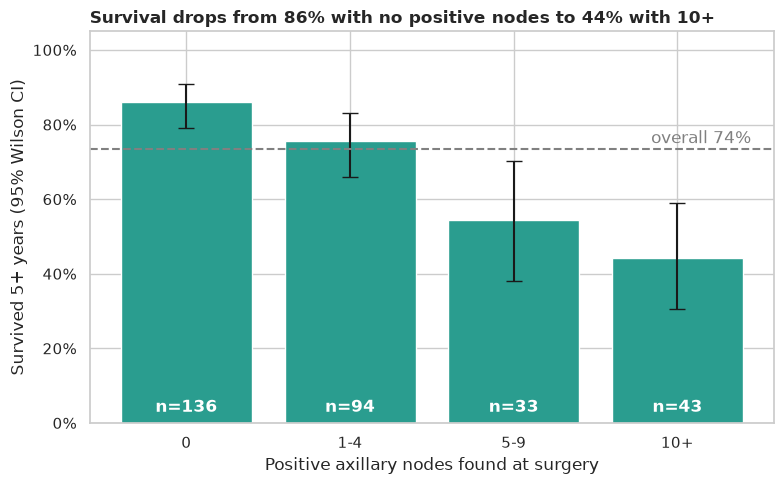

,n,survivors,rate,ci_low,ci_high
nodes,,,,,
0,136,117,0.860,0.792,0.909
1-4,94,71,0.755,0.660,0.831
5-9,33,18,0.545,0.380,0.702
10+,43,19,0.442,0.304,0.589


In [6]:
bins = pd.cut(df["nodes"], NODE_BIN_EDGES, labels=NODE_BIN_LABELS)
table = df.groupby(bins, observed=True)["survived"].agg(n="size", survivors="sum")
table["rate"] = table["survivors"] / table["n"]
table["ci_low"], table["ci_high"] = proportion_confint(
    table["survivors"], table["n"], method="wilson"
)
overall = df["survived"].mean()

fig, ax = plt.subplots(figsize=(8, 5))
err = [table["rate"] - table["ci_low"], table["ci_high"] - table["rate"]]
ax.bar(table.index.astype(str), table["rate"], yerr=err, capsize=6, color=COLORS["Survived 5y+"])
ax.axhline(overall, ls="--", color="grey")
ax.text(3.45, overall + 0.015, f"overall {overall:.0%}", ha="right", color="grey")
for i, n in enumerate(table["n"]):
    ax.text(i, 0.03, f"n={n}", ha="center", color="white", fontweight="bold")
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Positive axillary nodes found at surgery")
ax.set_ylabel("Survived 5+ years (95% Wilson CI)")
ax.set_title(
    f"Survival drops from {table['rate'].iloc[0]:.0%} with no positive nodes "
    f"to {table['rate'].iloc[-1]:.0%} with 10+",
    loc="left", fontweight="bold",
)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_survival_by_nodes.png", dpi=150)
plt.show()
table.round(3)

**How to read this.** Survival steps down as nodes go up: roughly **86% → 76% → 55% → 44%**. The 0-node and 1-4-node whiskers overlap a little, but the 0-node group sits clearly above the overall rate while the 10+ group sits clearly below it. The 5-9 and 10+ bins hold only 33 and 43 patients, so their whiskers are wide: the *direction* is solid, the exact percentages are not.

### 6b. The whole distribution: ECDF

*What:* an **ECDF** (empirical cumulative distribution function) shows, for each node count on the x-axis, **what share of the group has that many nodes or fewer**. *Why not a histogram?* With skewed counts, histogram bin choices change the story; the ECDF uses every data point and shows both groups on one clean picture. *How to read:* a curve that rises **sooner** belongs to the group with **smaller** values. The vertical gap between the curves is how different the groups are.

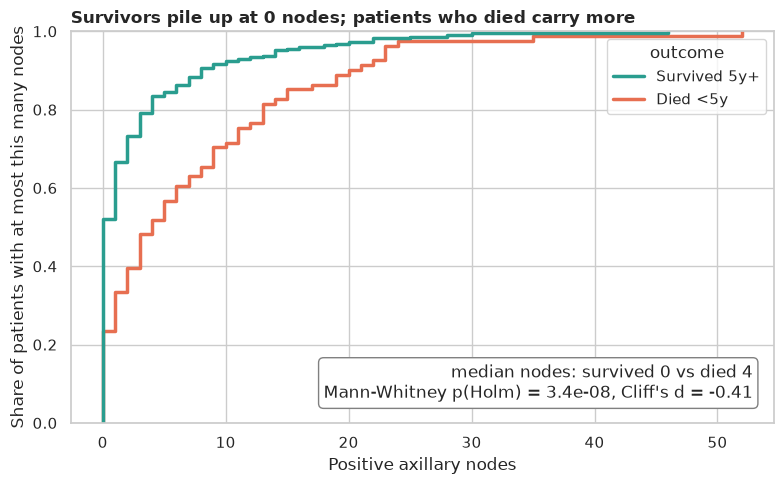

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.ecdfplot(df, x="nodes", hue="outcome", palette=COLORS, linewidth=2.5, ax=ax)
med = df.groupby("outcome")["nodes"].median()
t = tests.loc["nodes"]
ax.text(
    0.97, 0.05,
    f"median nodes: survived {med['Survived 5y+']:.0f} vs died {med['Died <5y']:.0f}\n"
    f"Mann-Whitney p(Holm) = {t['p_holm']:.1e}, Cliff's d = {t['cliffs_delta']:+.2f}",
    transform=ax.transAxes, ha="right", va="bottom",
    bbox={"boxstyle": "round", "fc": "white", "ec": "grey"},
)
ax.set_xlabel("Positive axillary nodes")
ax.set_ylabel("Share of patients with at most this many nodes")
ax.set_title("Survivors pile up at 0 nodes; patients who died carry more",
             loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "02_nodes_ecdf.png", dpi=150)
plt.show()

**How to read this.** At 0 nodes the green curve (survivors) already jumps to about **52%**, while the orange curve (died) starts at about **23%**: more than half of the survivors had a clean node check, against fewer than a quarter of the patients who died. The green curve stays above the orange one all the way up, which is exactly what "survivors tend to have fewer nodes" looks like. Both curves flatten near 100% by around 25 nodes, so the extreme values are rare.

### 6c. Age and year of surgery

*What:* box plots (the box holds the middle 50% of patients, the line is the median) with every patient overlaid as a faint dot. *Why show the dots?* Boxes can hide how much data sits behind them. *How to read:* if the two boxes sit at the same height and overlap, the feature does not separate the groups.

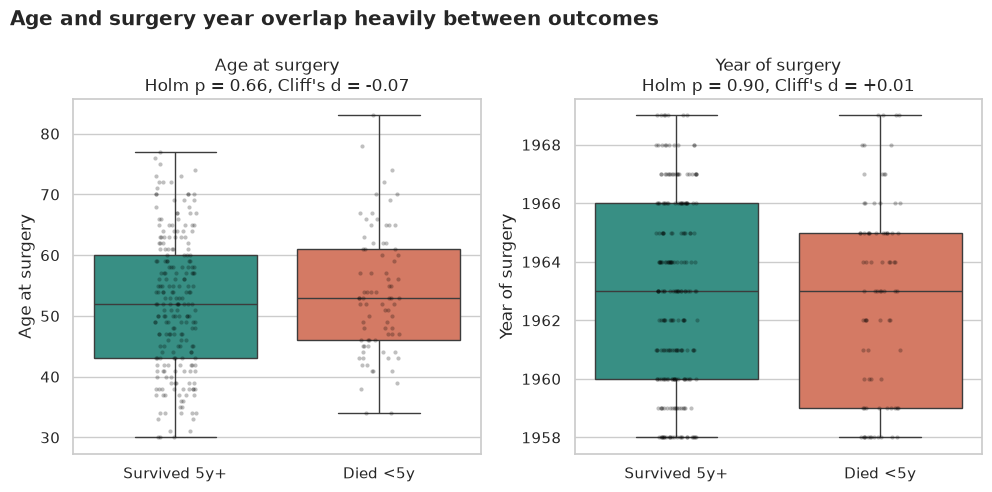

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, feature, label in zip(
    axes, ["age", "op_year"], ["Age at surgery", "Year of surgery"], strict=True
):
    sns.boxplot(df, x="outcome", y=feature, hue="outcome", palette=COLORS, fliersize=0,
                order=list(COLORS), ax=ax, legend=False)
    sns.stripplot(df, x="outcome", y=feature, color="black", alpha=0.25, size=3,
                  order=list(COLORS), ax=ax)
    t = tests.loc[feature]
    ax.set_title(f"{label}\nHolm p = {t['p_holm']:.2f}, Cliff's d = {t['cliffs_delta']:+.2f}")
    ax.set_xlabel("")
    ax.set_ylabel(label)
fig.suptitle("Age and surgery year overlap heavily between outcomes",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "03_age_year_overlap.png", dpi=150)
plt.show()

**How to read this.** For both features the boxes sit at nearly the same height with the same medians (about 52-53 years old; 1963), and the dots overlap almost completely. That matches the tests: p = 0.66 and 0.90. Knowing a patient's age or operation year barely helps you guess their outcome.

### 6d. A second test: chi-square on the node bins

*What:* the chi-square test of independence asks whether the **pattern of survivors across the four node bins** differs from what we would see if node count and survival were unrelated. *Why add it?* Mann-Whitney uses the raw counts. Chi-square looks at the binned version, so agreement between them makes the finding sturdier. **H₀:** survival is independent of node bin. **Hₐ:** it depends on node bin. *Check:* chi-square needs every cell's *expected* count to be at least about 5. *Effect size:* **Cramér's V** runs from 0 (unrelated) to 1 (perfectly related).

In [9]:
contingency = pd.crosstab(bins, df["survived"])
chi2, p_chi, dof, expected = stats.chi2_contingency(contingency)
cramers_v = np.sqrt(chi2 / (contingency.to_numpy().sum() * (min(contingency.shape) - 1)))
print(f"chi2({dof}) = {chi2:.1f}, p = {p_chi:.1e}, Cramér's V = {cramers_v:.2f}")
print(f"Smallest expected cell count: {expected.min():.1f}  (should be >= 5)")
contingency

chi2(3) = 36.2, p = 6.6e-08, Cramér's V = 0.34
Smallest expected cell count: 8.7  (should be >= 5)


survived,0,1
nodes,,
0,19,117
1-4,23,71
5-9,15,18
10+,24,19


**How to read this.** χ²(3) ≈ 36.2 and p ≈ 7e-08, so we **reject H₀** again: survival depends on node bin. Cramér's V ≈ 0.34 is a medium association. The smallest expected cell count is about 8.7, above the rule-of-thumb minimum of 5, so the test is trustworthy here.

## 7. A baseline model, with no cheating

*What:* the tests show nodes *separate* the groups. Now we ask the practical question: **can a model use features known on surgery day to predict who survives, better than a lazy guess?**

We build a small "ladder" of models:

1. **Majority class**: always predict "survived". This is the bar to beat.
2. **Logistic regression on nodes only** (using `log1p(nodes)` so the long tail does not dominate).
3. **Logistic regression on nodes + age + year.**

**How we avoid cheating (data leakage).** If you scale or transform *all* the data first and then split it, the test patients have secretly influenced the training step, like a student who saw the exam questions while making study notes. Putting every transform **inside** an sklearn `Pipeline` means it is re-fitted on the training patients only, in every fold.

**How we score.** We use **ROC-AUC**: the chance the model gives a higher "survival" score to a random survivor than to a random non-survivor (0.5 = coin flip, 1.0 = perfect). It does not care about the 73.5/26.5 imbalance. We use **5-fold cross-validation repeated 10 times** (50 train/test splits) for stable numbers.

**Why the "Nadeau-Bengio" correction?** The 50 test scores are not independent: every split reuses mostly the same patients for training. Like several judges who all read the same pages of a report, their scores agree more than independent judges would, so a plain confidence interval is *too narrow*. The correction widens it to be honest.

In [10]:
def log_nodes() -> FunctionTransformer:
    """Returns a transformer applying log(1 + x), which tames long right tails."""
    return FunctionTransformer(np.log1p, feature_names_out="one-to-one")


def build_models() -> dict[str, Pipeline]:
    """Builds the model ladder. Every transform lives inside its Pipeline (no leakage).

    Returns:
        Model name mapped to an unfitted sklearn Pipeline.
    """
    nodes_only = ColumnTransformer([("nodes", log_nodes(), ["nodes"])])
    all_features = ColumnTransformer(
        [("nodes", log_nodes(), ["nodes"]), ("rest", StandardScaler(), ["age", "op_year"])]
    )
    return {
        "Majority class (no skill)": Pipeline([("model", DummyClassifier(strategy="prior"))]),
        "Logistic: nodes only": Pipeline(
            [("prep", nodes_only), ("model", LogisticRegression(max_iter=1000))]
        ),
        "Logistic: nodes + age + year": Pipeline(
            [("prep", all_features), ("model", LogisticRegression(max_iter=1000))]
        ),
    }


def corrected_ci(scores: np.ndarray, n_train: int, n_test: int) -> tuple[float, float, float]:
    """95% CI for a mean CV score using the Nadeau-Bengio variance correction.

    Args:
        scores: Per-split scores.
        n_train: Training rows per split.
        n_test: Test rows per split.

    Returns:
        Mean, CI lower bound, CI upper bound.
    """
    k = len(scores)
    se = np.sqrt((1 / k + n_test / n_train) * np.var(scores, ddof=1))
    half = stats.t.ppf(0.975, k - 1) * se
    return float(scores.mean()), float(scores.mean() - half), float(scores.mean() + half)


def corrected_paired_p(diff: np.ndarray, n_train: int, n_test: int) -> float:
    """Two-sided p-value for 'do two models differ?' on identical splits.

    Args:
        diff: Per-split score differences between two models.
        n_train: Training rows per split.
        n_test: Test rows per split.

    Returns:
        p-value from the corrected resampled t-test.
    """
    k = len(diff)
    se = np.sqrt((1 / k + n_test / n_train) * np.var(diff, ddof=1))
    return float(2 * stats.t.sf(abs(diff.mean() / se), k - 1))

Now run the cross-validation. All three models see **exactly the same 50 splits**, which is what lets us compare them in a *paired* way afterwards. We record both ROC-AUC and plain accuracy, because accuracy is what the "always guess survived" baseline is best at.

In [11]:
X, y = df[["age", "op_year", "nodes"]], df["survived"]
cv = RepeatedStratifiedKFold(n_splits=CV_SPLITS, n_repeats=CV_REPEATS, random_state=SEED)
n_test = len(df) // CV_SPLITS
n_train = len(df) - n_test

auc_scores, summary = {}, {}
for name, model in build_models().items():
    auc = cross_val_score(model, X, y, cv=cv, scoring="roc_auc")
    acc = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    auc_scores[name] = auc
    (a, a_lo, a_hi), (c, c_lo, c_hi) = (
        corrected_ci(auc, n_train, n_test), corrected_ci(acc, n_train, n_test)
    )
    summary[name] = {"AUC": a, "AUC low": a_lo, "AUC high": a_hi,
                     "Accuracy": c, "Acc low": c_lo, "Acc high": c_hi}

pd.DataFrame(summary).T.round(3)

,AUC,AUC low,AUC high,Accuracy,Acc low,Acc high
Majority class (no skill),0.500,0.500,0.500,0.735,0.730,0.740
Logistic: nodes only,0.705,0.647,0.762,0.745,0.711,0.779
Logistic: nodes + age + year,0.706,0.646,0.765,0.753,0.720,0.785


**How to read this.**

- The majority-class row has AUC **0.50**, by construction: it has no skill. Its accuracy is **73.5%**, the bar to beat.
- **Nodes only** reaches AUC **≈ 0.70** (95% CI roughly 0.65 to 0.76). The whole interval sits above 0.5, so the model has real, but **modest**, ranking skill.
- The **accuracy** gain is small: about **74.5%** (CI roughly 71% to 78%) against 73.5%. The interval includes the baseline, so we should *not* claim the model is more accurate than guessing "survived". It is better at **ordering** patients by risk than at **classifying** them.

That second point is a lesson in itself: a model can be useful for ranking and still look unimpressive on accuracy when one class dominates.

## 8. Iteration: do age and year help a bigger model?

*What:* test two claims with the **paired corrected t-test**, which compares models split by split.

1. **Nodes-only vs majority class**: is the skill real?
2. **All features vs nodes-only**: do age and year add anything?

The tests in section 5 already predicted the answer to the second question: those two features did not separate the groups.

nodes-only vs majority class : p = 3.5e-09
all features vs nodes-only   : p = 0.92


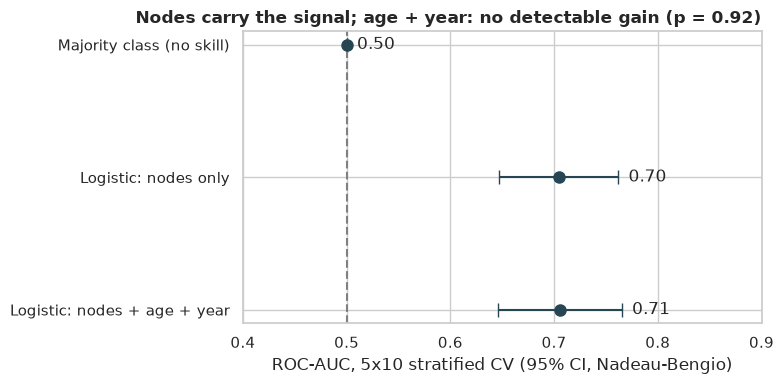

In [12]:
names = list(auc_scores)
p_skill = corrected_paired_p(auc_scores[names[1]] - auc_scores[names[0]], n_train, n_test)
p_extra = corrected_paired_p(auc_scores[names[2]] - auc_scores[names[1]], n_train, n_test)
print(f"nodes-only vs majority class : p = {p_skill:.1e}")
print(f"all features vs nodes-only   : p = {p_extra:.2f}")

fig, ax = plt.subplots(figsize=(8, 4))
for i, name in enumerate(names):
    m = summary[name]
    ax.errorbar(m["AUC"], i, xerr=[[m["AUC"] - m["AUC low"]], [m["AUC high"] - m["AUC"]]],
                fmt="o", color="#264653", capsize=5, markersize=8)
    ax.text(m["AUC high"] + 0.01, i, f"{m['AUC']:.2f}", va="center")
ax.axvline(0.5, ls="--", color="grey")
ax.set_yticks(range(len(names)), names)
ax.invert_yaxis()
ax.set_xlim(0.4, 0.9)
ax.set_xlabel(f"ROC-AUC, {CV_SPLITS}x{CV_REPEATS} stratified CV (95% CI, Nadeau-Bengio)")
ax.set_title(f"Nodes carry the signal; age + year: no detectable gain (p = {p_extra:.2f})",
             loc="right", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "04_model_comparison.png", dpi=150)
plt.show()

**How to read this.**

- **Nodes-only vs majority class: p ≈ 3.5e-09.** The skill is real; it is not a fluke of the splits.
- **All features vs nodes-only: p ≈ 0.92.** Adding age and year changes the AUC from about 0.705 to 0.706. That is no detectable gain. The two error bars overlap almost completely.

This is the "data storytelling over model churn" point: a bigger model was not the answer. The *right feature* was. Piling on more inputs did nothing, because the earlier tests had already shown they carry no signal.

## 9. 🎯 Takeaways

1. **Positive axillary nodes are the one feature that separates the groups.** Median 0 nodes for survivors vs 4 for those who died (δ ≈ −0.41, Holm p ≈ 3e-08); survival falls from about 86% to 44% across node bins.
2. **Age and year of surgery show no detectable relationship** with 5-year survival in this sample (p = 0.66 and 0.90). That is "no evidence", not "evidence of none".
3. **A simple model ranks patients with modest skill** (AUC ≈ 0.70) but is **not more accurate** than always guessing "survived" (74.5% vs 73.5%).
4. **Adding more features did not help** (paired p ≈ 0.92). The effort belongs in understanding *which* variable matters.

## 10. ⚠️ Limitations and edge cases

- **Association, not causation.** Node count reflects how advanced the cancer was; the nodes themselves are not what causes death.
- **Small and old.** 306 patients from one hospital in 1958-1970. Screening and treatment have changed enormously since.
- **A yes/no outcome only.** There are no follow-up times, so proper survival analysis (Kaplan-Meier curves, Cox regression) is not possible with this file.
- **17 duplicate rows.** They are likely distinct patients, but if a twin lands in the test fold while its copy is in training, the cross-validation scores are slightly optimistic.
- **Uncalibrated probabilities.** We never checked that "70% predicted survival" means 70% actually survive, so do not read the scores as individual risk.
- **Three tests, one dataset.** Holm corrects for these three comparisons, not for every exploratory look one could take.

---
*Run `uv run jupyter nbconvert --to html --execute ML/haberman-survival/haberman_survival.ipynb` to rebuild the web version (`docs/ml-haberman.html`).*